# BT4012 — Submission diagnostics

## tl;dr
All three scored files reproduce to floating-point precision in the original Python 3.10 environment. V2 remains the incumbent at **0.94785 public ROC-AUC**. V3 gains concentrate in particular historical periods; its overall validation ranking did not transfer. The fixed new graph ensemble failed its advancement rule.

## Context & Methods
Public scores were confirmed by the user: V1 0.94719, V2 0.94785, V3 0.94510. No other scored submissions exist. Reconstructed models use three 14-step windows; the middle window overlaps both others. All are retrospective diagnostics.

### Key Assumptions
Unknown labels are excluded. Provided graph features are explicitly allowed by the pasted competition description. First-94/last-71 feature semantics are unverified. No test labels or external labels are used. Exact reproduction uses `requirements-original.txt`.

### Reproduce
Run `python diagnose_submissions.py --run-id NEW_NAME` in `experiments/` to refit the models. The summary script currently targets `runs/submission_diagnosis`; update that path for a different run. This notebook reads the saved run and recomputes the key comparison tables. Full details: `SUBMISSION_FINDINGS.md`.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
HERE=Path.cwd() if (Path.cwd()/'pipeline.py').exists() else Path.cwd()/'experiments'
RUN=HERE/'runs/submission_diagnosis'
assert (RUN/'COMPLETE').exists()
print('Diagnostic source:', RUN.resolve())

Diagnostic source: /Users/melodygoh/bt4012_kaggle/experiments/runs/submission_diagnosis


## Data
The provided train/test/edge/sample files are recorded by hash in the manifest. Public scores are user-confirmed; prediction reproducibility is measured separately.

In [2]:
display(pd.read_csv(RUN/'leaderboard.csv')[['model','filename','public_roc_auc']])
display(pd.read_csv(RUN/'submission_reproduction.csv'))
manifest=json.loads((RUN/'manifest.json').read_text())
display(pd.Series(manifest['versions'],name='Version').to_frame())

,model,filename,public_roc_auc
0,v1,submission_lgbm_v1.csv,0.94719
1,v2,submission_v2.csv,0.94785
2,v3,submission_v3.csv,0.94510


,model,max_absolute_difference,mean_absolute_difference,matches_at_1e_10
0,v1,1.110223e-16,3.198284e-17,True
1,v2,1.110223e-16,3.488632e-17,True
2,v3,1.110223e-16,4.733819e-17,True


,Version
numpy,1.25.2
pandas,2.0.3
lightgbm,4.7.0
scikit-learn,1.6.1


## Results
### Model ranking changes with the evaluation period

,Train through 7,Train through 14,Train through 21,Kaggle public
model,,,,
v1,0.993416,0.965639,0.892850,0.94719
v2,0.993046,0.965982,0.901627,0.94785
v3,0.992073,0.973443,0.913116,0.94510


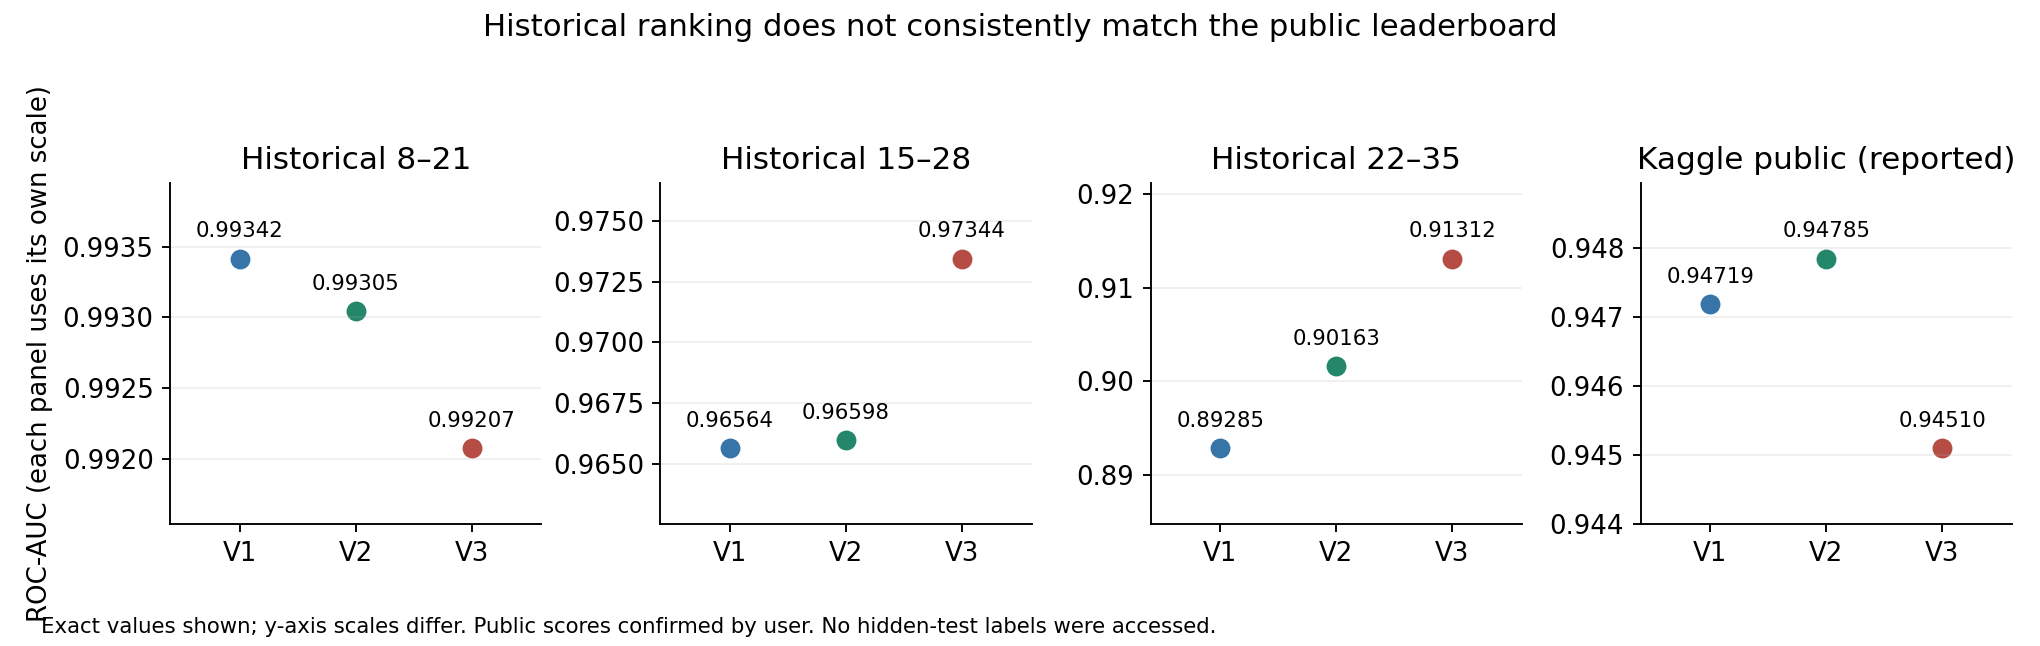

In [3]:
metrics=pd.read_csv(RUN/'metrics.csv')
table=metrics[metrics.model.isin(['v1','v2','v3'])].pivot(index='model',columns='train_end',values='roc_auc')
table.columns=[f'Train through {x}' for x in table.columns]
table['Kaggle public']=pd.read_csv(RUN/'leaderboard.csv').set_index('model').public_roc_auc
display(table.round(6))
display(Image(filename=str(RUN/'local_vs_public_auc.png')))

Historical V3 gains are not uniformly transferable. Public V2 is lower than one local window and higher than another; there is no defensible fixed correction from validation to Kaggle.

### Gains concentrate in particular time steps

,train_end,steps_improved,steps_worsened,steps_tied,macro_v2_auc,macro_v3_auc
0,7,3,11,0,0.992182,0.991157
1,14,7,7,0,0.965087,0.970301
2,21,3,10,1,0.923840,0.929646


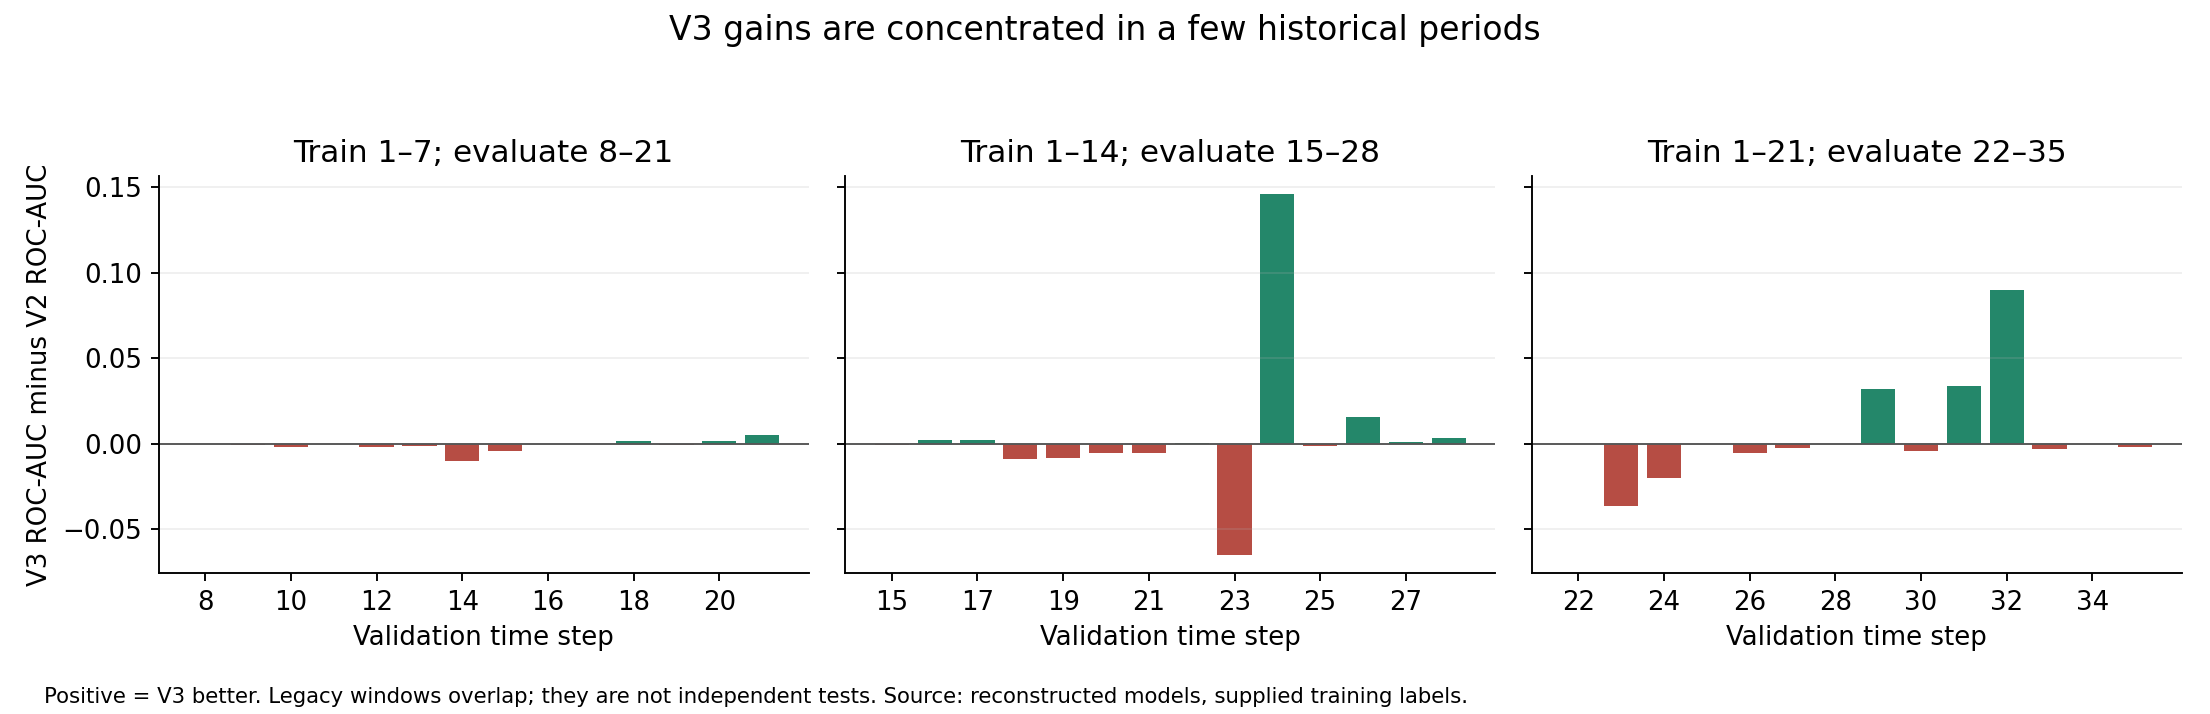

,train_end,excluded_step,v3_minus_v2_auc
23,14,24,-0.004173
38,21,32,0.003667


In [4]:
display(pd.read_csv(RUN/'step_win_loss_summary.csv').round(6))
display(Image(filename=str(RUN/'per_step_auc_changes.png')))
loo=pd.read_csv(RUN/'leave_one_step_out_diagnostic.csv')
display(loo[((loo.train_end==14)&(loo.excluded_step==24)) | ((loo.train_end==21)&(loo.excluded_step==32))].round(6))

Removing step 24 flips the train-through-14 V3 advantage to a loss. This is a sensitivity diagnostic, not permission to remove difficult periods from evaluation. Pairwise AUC is not additive across steps.

### Historical uncertainty

In [5]:
display(pd.read_csv(RUN/'historical_bootstrap.csv').round(6))

,train_end,v3_minus_v2_auc,cluster_bootstrap_2.5pct,cluster_bootstrap_97.5pct,replicates
0,7,-0.000973,-0.002110,0.000405,1000
1,14,0.007461,-0.007903,0.036037,1000
2,21,0.011489,-0.004414,0.032431,1000


Paired resampling of whole time steps, 1,000 draws, seed 42. All percentile intervals include zero. These intervals do not capture adjacent-step dependence or future shift and are not forecasts of Kaggle uncertainty.

### Test ranking and cross-period ordering

In [6]:
display(pd.read_csv(RUN/'submission_rank_correlations.csv',index_col=0).round(6))
pairs=pd.read_csv(RUN/'auc_pair_decomposition.csv')
display(pairs[pairs.model.isin(['v2','v3'])].round(6))

,v1,v2,v3
v1,1.000000,0.982561,0.696541
v2,0.982561,1.000000,0.723310
v3,0.696541,0.723310,1.000000


,train_end,model,within_step_pair_share,within_step_pair_auc,cross_step_pair_auc
1,7,v2,0.068388,0.990796,0.993211
5,7,v3,0.068388,0.990410,0.992195
7,14,v2,0.077820,0.953177,0.967063
11,14,v3,0.077820,0.967286,0.973963
13,21,v2,0.086285,0.874421,0.904196
17,21,v3,0.086285,0.897690,0.914572


V3 changes the ordering much more than adding V2 graph features did. Correlation alone cannot identify correctness. Roughly 91–93% of historical positive/negative pairs cross time steps, so both pooled and per-step AUC deserve review.

### New fixed graph-only ensemble

In [7]:
candidate=HERE/'runs/graph_bagging_initial'
assert (candidate/'COMPLETE').exists()
display(pd.read_csv(candidate/'metrics.csv').pivot(index='train_end',columns='model',values='roc_auc').round(6))
print(json.loads((candidate/'decision.json').read_text()))

model,candidate,v2
train_end,,
7,0.993778,0.993046
14,0.967241,0.965982
21,0.900093,0.901627


{'advance': False, 'rule': 'Both legacy origins (14,21) must improve pooled AUC; origin 7 must not lose more than 0.001. This is a retrospective screening rule, not proof of hidden-test gain.', 'deltas': {'7': 0.0007319771345926096, '14': 0.0012581533035367354, '21': -0.0015337799575181332}}


The candidate improves two windows but loses on train-through-21 evaluation. It fails the frozen advancement criterion, so no submission was generated.

### Original-file preservation

In [8]:
sys.path.insert(0,str(HERE))
from pipeline import sha256
original=json.loads((HERE/'original_checksums.json').read_text())
changed=[name for name,digest in original.items() if sha256(HERE.parent/name)!=digest]
assert not changed, changed
print(f'{len(original)} original files unchanged.')

25 original files unchanged.


## Takeaways
Keep V2 as the incumbent. Require broader historical robustness before promoting a candidate; do not trust a gain driven by one period. The next planned direction is training-only feature stability selection, not a larger sweep against reused folds. Three public scores cannot ensure a 0.96+ hidden-test result. No new submission was made.